In [1]:
import torch
import torchvision
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt
import cv2

from torchvision.models import resnet18
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

In [5]:
import os

print(os.getcwd())
print(os.path.exists("../models/resnet18_finetuned.pth"))

g:\DL-Assignment-3\notebooks
False


In [6]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load model
model = resnet18(pretrained=False)
model.fc = torch.nn.Linear(model.fc.in_features, 10)  

model.load_state_dict(torch.load("../models/resnet18_stl10.pth", map_location=device))
model.to(device)
model.eval()

g:\DL-Assignment-3\venv\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
g:\DL-Assignment-3\venv\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [7]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

test_dataset = torchvision.datasets.STL10(
    root="./data",
    split="test",
    download=True,
    transform=transform
)

test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=1, shuffle=False)

100%|██████████| 2.64G/2.64G [24:15<00:00, 1.81MB/s]   


In [8]:
target_layer = model.layer4[-1] 

cam = GradCAM(model=model, target_layers=[target_layer])

In [9]:
correct_samples = []
incorrect_samples = []

for img, label in test_loader:
    img = img.to(device)
    
    output = model(img)
    pred = torch.argmax(output, dim=1)

    if pred.item() == label.item() and len(correct_samples) < 2:
        correct_samples.append((img, label, pred))
    
    elif pred.item() != label.item() and len(incorrect_samples) < 2:
        incorrect_samples.append((img, label, pred))

    if len(correct_samples) == 2 and len(incorrect_samples) == 2:
        break

In [10]:
def visualize_cam(img_tensor, label, pred, title):
    img = img_tensor.squeeze().cpu().numpy().transpose(1, 2, 0)
    
    # Normalize for visualization
    img = (img - img.min()) / (img.max() - img.min())

    grayscale_cam = cam(input_tensor=img_tensor)[0]

    cam_image = show_cam_on_image(img, grayscale_cam, use_rgb=True)

    plt.imshow(cam_image)
    plt.title(f"{title}\nTrue: {label.item()} | Pred: {pred.item()}")
    plt.axis("off")

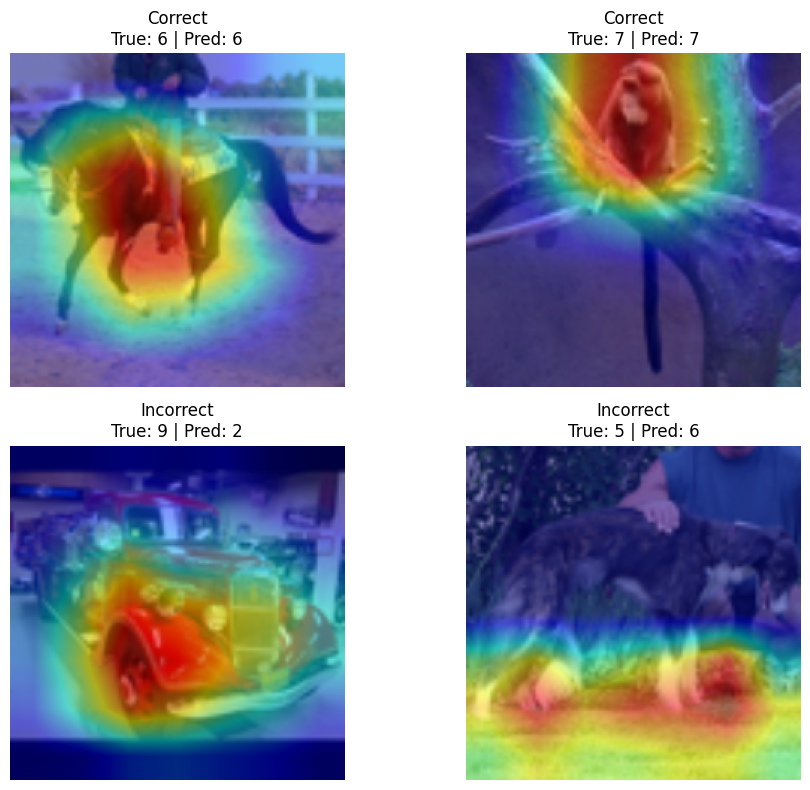

In [ ]:
plt.figure(figsize=(10, 8))

# Correct pred
for i, (img, label, pred) in enumerate(correct_samples):
    plt.subplot(2, 2, i+1)
    visualize_cam(img, label, pred, "Correct")

# Incorrect pred
for i, (img, label, pred) in enumerate(incorrect_samples):
    plt.subplot(2, 2, i+3)
    visualize_cam(img, label, pred, "Incorrect")

plt.tight_layout()
plt.show()